# SmartCook: End-to-End Machine Learning Pipeline
**Sistem Rekomendasi Resep Berbasis Bahan, Klasifikasi Kategori Resep, dan Filter Diet Personal Berbasis BMI × TDEE**

Notebook ini mengimplementasikan dan mengevaluasi 3 modul Machine Learning utama untuk aplikasi **SmartCook** menggunakan dataset `resep_nutrisi_recount.csv` (5.732 resep kuliner Indonesia):

| Modul | Fitur & Tujuan | Algoritma / Metode ML | Skenario Aplikasi |
|---|---|---|---|
| **1. Rekomendasi Berbasis Bahan** *(Fungsi Utama)* | Menjawab "Punya bahan A, B, C bisa masak apa?", menghitung kecocokan bahan dimiliki vs kurang. | **TF-IDF + Cosine Similarity** (Content-Based Filtering) dibandingkan dengan CountVectorizer & IDF-Overlap. | Pengguna menginputkan bahan di kulkas, sistem meranking resep dengan % kecocokan dan detail bahan kurang. |
| **2. Klasifikasi Kategori Resep** *(Klasifikasi Teks)* | Mengelompokkan resep ke dalam 8 kategori protein utama (*ayam, sapi, ikan, udang, telur, tahu, tempe, kambing*). | **Logistic Regression** dan **Multinomial Naive Bayes** berbasis TF-IDF. | Auto-Tagging resep baru pengguna (*User Generated Content*) dan filter cepat berbasis protein. |
| **3. Filter Diet Personal (BMI × TDEE)** *(Fitur Nilai Tambah)* | Menentukan kategori diet personal pengguna (*Diet Ketat, Diet Ringan, Maintenance, Bulking*) berdasarkan skor BMI × TDEE, lalu memfilter resep yang sesuai batas kalori. | **Decision Tree Classifier** & **Multinomial Logistic Regression** pada profil pengguna + Mifflin-St Jeor TDEE. | Membantu pengguna dengan berbagai status gizi (underweight, normal, overweight, obesitas) mendapatkan rekomendasi resep yang sesuai kebutuhan kalori harian. |

---
**Alur Eksekusi:** Pemuatan & Validasi Data → Praproses Teks Bahan → Pembagian Data (80:20 Stratified) → [Modul 1] Mesin Rekomendasi & Pelacak Bahan → Tuning & Evaluasi Keterambilan → [Modul 2] Klasifikasi Kategori & Auto-Tagging → [Modul 3] Filter Diet Personal BMI × TDEE → [Integrasi Utuh] SmartCook Unified Engine → **Interactive Playground (Live Testing)** → Ekspor Model & Ringkasan Laporan.

## Bagian 0: Persiapan Lingkungan & Pustaka Dependensi
Memuat pustaka standar data science: `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`, dan `seaborn`.
Sistem secara otomatis mendeteksi apakah berkas dijalankan di Google Colab atau di lingkungan lokal.

In [1]:
import os, re, random, time, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy import sparse

# Machine Learning & Evaluasi dari Scikit-Learn
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# Atur seed agar hasil eksperimen konsisten (reproducible)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Pengaturan visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Deteksi lokasi dataset: prioritaskan /content/resep_nutrisi_recount.csv untuk Google Colab
POSSIBLE_PATHS = [
    '/content/resep_nutrisi_recount.csv',
    'resep_nutrisi_recount.csv',
    os.path.join('machine_learning', 'resep_nutrisi_recount.csv'),
    '/content/drive/MyDrive/resep_nutrisi_recount.csv'
]

CSV_FILENAME = None
for p in POSSIBLE_PATHS:
    if os.path.exists(p):
        CSV_FILENAME = p
        break

if CSV_FILENAME is None:
    # Default fallback ke path Google Colab
    CSV_FILENAME = '/content/resep_nutrisi_recount.csv'

print(f"Berkas dataset yang digunakan: {CSV_FILENAME}")
print("Semua pustaka berhasil dimuat dengan sukses.")


Berkas dataset yang digunakan: resep_nutrisi_recount.csv
Semua pustaka berhasil dimuat dengan sukses.


## Bagian 1: Memuat Data & Eksplorasi Dataset (`resep_nutrisi_recount.csv`)
Dataset `resep_nutrisi_recount.csv` memuat resep masakan Indonesia (sumber Cookpad) dengan kolom `Title`, `Ingredients` (teks mentah), `Steps`, `URL`, `Category` (bahan utama), `Ingredients Normalized` (bahan yang sudah dinormalisasi, dipisah ` , `), `Total Steps`, serta fitur nutrisi numerik (`kalori_kkal`, `protein_g`, `lemak_g`, `karbohidrat_g`) beserta kolom bantu (`berat_g`, `cakupan_bahan`, `jumlah_baris_bahan`, `kalori_per100g_bahan`).

> [!NOTE]
> **Perbedaan dengan dataset sebelumnya:**
> 1. Berkas memakai delimiter **koma (`,`)**, bukan titik koma.
> 2. Kolom bahan bersih bernama **`Ingredients Normalized`** (sebelumnya `Ingredients Cleaned`).
> 3. Nilai nutrisi sudah dalam **satuan riil** (kkal dan gram per resep), sehingga **tidak perlu dibagi 10** lagi.
> 4. Ada **5 resep yang barisnya pecah** (kolom `Steps` berisi tanda kutip yang tidak seimbang sehingga langkah memasak terbaca sebagai baris baru dengan kolom bergeser). Baris-baris ini dibuang pada tahap pembersihan di bawah, karena kolom `Category`, `URL`, dan nutrisinya tidak lagi sejajar.
> 5. Terdapat beberapa baris dengan nutrisi bernilai 0 (tidak terhitung) yang juga dibuang.

In [2]:
# Memuat dataset (delimiter koma). Kolom 'Steps' memuat baris baru di dalam tanda kutip.
df_raw = pd.read_csv(CSV_FILENAME, encoding='utf-8-sig')
print(f"Baris terbaca mentah         : {len(df_raw):,}")
print(f"Kolom dalam dataset          : {list(df_raw.columns)}")

# --- Pembersihan struktur: buang baris yang pecah / kolomnya bergeser ---
KATEGORI_VALID = {'ayam', 'sapi', 'ikan', 'udang', 'telur', 'tahu', 'tempe', 'kambing'}
mask_valid = df_raw['Category'].isin(KATEGORI_VALID) & ~df_raw['Title'].astype(str).str.match(r'^\d+\)')
print(f"Baris rusak (kolom bergeser) : {(~mask_valid).sum():,} baris dibuang")
df = df_raw[mask_valid].copy()

# Pastikan fitur nutrisi bertipe numerik (nilai sudah dalam satuan riil, TIDAK perlu dibagi 10)
KOLOM_NUTRISI = ['kalori_kkal', 'protein_g', 'lemak_g', 'karbohidrat_g']
for col in KOLOM_NUTRISI + ['berat_g']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Buang resep tanpa data nutrisi valid (kalori kosong atau 0)
mask_nutrisi = df[KOLOM_NUTRISI].notna().all(axis=1) & (df['kalori_kkal'] > 0)
print(f"Resep tanpa nutrisi valid    : {(~mask_nutrisi).sum():,} resep dibuang")
df = df[mask_nutrisi].reset_index(drop=True)
df['id'] = np.arange(len(df))

# Kolom 'nyata' dipertahankan agar seluruh fungsi di bawah tetap kompatibel
df['kalori_nyata'] = df['kalori_kkal'].round(1)
df['protein_nyata'] = df['protein_g'].round(1)
df['lemak_nyata'] = df['lemak_g'].round(1)
df['karbohidrat_nyata'] = df['karbohidrat_g'].round(1)

print(f"\nTotal resep bersih untuk dimodelkan: {len(df):,}")
print("\nDistribusi Resep per Kategori Bahan Utama:")
dist_kat = df['Category'].value_counts()
print(dist_kat.to_string())

# Tampilkan 3 sampel teratas
df[['Title', 'Category', 'Ingredients Normalized', 'kalori_nyata', 'protein_nyata', 'lemak_nyata', 'karbohidrat_nyata']].head(3)

Baris terbaca mentah         : 5,764
Kolom dalam dataset          : ['Title', 'Ingredients', 'Steps', 'URL', 'Category', 'Ingredients Normalized', 'Total Steps', 'kalori_kkal', 'protein_g', 'lemak_g', 'karbohidrat_g', 'berat_g', 'cakupan_bahan', 'jumlah_baris_bahan', 'kalori_per100g_bahan']
Baris rusak (kolom bergeser) : 30 baris dibuang
Resep tanpa nutrisi valid    : 2 resep dibuang

Total resep bersih untuk dimodelkan: 5,732

Distribusi Resep per Kategori Bahan Utama:
Category
tempe      864
udang      836
ikan       747
telur      731
sapi       698
ayam       659
tahu       619
kambing    578


                                     Title Category                                                                                                                                                                      Ingredients Normalized  kalori_nyata  protein_nyata  lemak_nyata  karbohidrat_nyata
0                         Ayam cabai kawin     ayam                                                                                 ayam , cabai hijau , cabai merah , bawang putih , bawang merah , gula , garam , tomat , air , minyak goreng         987.0           47.8         78.2               19.8
1                  Ayam Saus Hintalu Jaruk     ayam                                            ayam , telur asin , cabai merah , cabai hijau , tepung terigu , lada , bawang putih , jeruk nipis , minyak goreng , gula , garam , penyedap rasa        2859.0          124.6        146.4              249.8
2  Ayam Bakar Pedas Manis Resep :Nila Sari     ayam  ayam , bawang merah , cabai , jahe , kunyit 

## Bagian 2: Praproses Teks Bahan Resep (Text Preprocessing)
Kolom `Ingredients Normalized` memuat daftar bahan yang dipisahkan koma. Praproses yang dirancang:
1. **Case folding & Pembersihan Karakter:** Mengubah teks menjadi huruf kecil dan membuang tanda baca/angka asing.
2. **Normalisasi Ejaan Kata Indonesia:** Menyelaraskan kata tidak baku ke bentuk baku (`cabe` → `cabai`, `telor` → `telur`, `saos` → `saus`, `asem` → `asam`, `bombay` → `bombai`, dll.) sehingga input pengguna selalu cocok dengan database resep.
3. **Penyaringan Stopwords Khusus Dapur:** Membuang kata tak bermakna bahan seperti takaran (`sdm`, `sdt`, `kg`, `gr`, `secukupnya`, `iris tipis`, `dihaluskan`, dll.).
4. **Custom Tokenizer/Analyzer:** Mengekstrak **unigram dan bigram di dalam lingkup satu bahan** (terpisah koma). Dengan demikian, frasa *"bawang putih"* atau *"cabai rawit"* tetap dianalisis sebagai satu kesatuan tanpa tercampur dengan bahan di sebelahnya.

In [3]:
NORMALISASI = {
    'cabe': 'cabai', 'telor': 'telur', 'saos': 'saus', 'asem': 'asam',
    'bombay': 'bombai', 'trasi': 'terasi', 'baput': 'bawang putih',
    'bamer': 'bawang merah', 'daun jeruk purut': 'daun jeruk',
    'royko': 'penyedap', 'masako': 'penyedap', 'micin': 'penyedap'
}

STOPWORDS_DAPUR = set(
    'secukupnya secukup sdm sdt gr gram kg ml buah siung biji iris tipis halus sedikit untuk dan atau yang '
    'dengan suka jika sesuai selera potong ukuran sedang besar kecil sebutir lembar ruas butir bungkus bks '
    'sachet ekor batang dipotong diiris dihaluskan dicincang dimemarkan dikupas dicuci disuwir direbus digeprek'.split()
)

def bersihkan_frasa(frasa):
    """Membersihkan satu frasa bahan, normalisasi kata, dan buang stopwords."""
    frasa = re.sub(r'[^a-z\s]', ' ', str(frasa).lower())
    tokens = [NORMALISASI.get(t, t) for t in frasa.split() if t not in STOPWORDS_DAPUR and len(t) > 1]
    return " ".join(tokens)

def buat_analyzer(maks_ngram=2):
    """Analyzer yang mengekstrak unigram & bigram dalam batasan koma."""
    def analyzer(doc):
        terms = []
        for frasa in str(doc).split(','):
            b = bersihkan_frasa(frasa)
            tokens = b.split()
            terms += tokens
            if maks_ngram >= 2:
                terms += [a + ' ' + b for a, b in zip(tokens, tokens[1:])]
        return terms
    return analyzer

df['doc'] = df['Ingredients Normalized'].fillna('').astype(str)

print("Contoh Teks Asli Resep 0:")
print(df.loc[0, 'Ingredients Normalized'])
print("\nHasil Tokenisasi Custom Analyzer (Unigram + Bigram):")
print(buat_analyzer(2)(df.loc[0, 'Ingredients Normalized']))

Contoh Teks Asli Resep 0:
ayam , cabai hijau , cabai merah , bawang putih , bawang merah , gula , garam , tomat , air , minyak goreng

Hasil Tokenisasi Custom Analyzer (Unigram + Bigram):
['ayam', 'cabai', 'hijau', 'cabai hijau', 'cabai', 'merah', 'cabai merah', 'bawang', 'putih', 'bawang putih', 'bawang', 'merah', 'bawang merah', 'gula', 'garam', 'tomat', 'air', 'minyak', 'goreng', 'minyak goreng']


## Bagian 3: Pembagian Data (Train-Dev-Test 80:20 Stratified)
Sesuai metodologi machine learning yang ketat:
- **80% Data Pengembangan (`idx_dev` / 4.585 resep):** Digunakan untuk fitting model, representasi vektor TF-IDF, serta tuning hyperparameter melalui validasi silang (fit: 3.668, val: 917).
- **20% Data Pengujian (`idx_test` / 1.147 resep):** Disimpan terisolasi (*unseen test set*) dan hanya diuji satu kali di akhir untuk mengukur performa generalisasi yang objektif.
- Pembagian dilakukan secara **stratified** terhadap kolom `Category` agar proporsi 8 kategori protein tetap seimbang.

In [4]:
# Pembagian stratified 80% dev dan 20% test
idx_dev, idx_test = train_test_split(df['id'].values, test_size=0.2, random_state=SEED, stratify=df['Category'])

# Pembagian data pengembangan menjadi 80% fit dan 20% validation
idx_fit, idx_val = train_test_split(idx_dev, test_size=0.2, random_state=SEED, stratify=df.loc[idx_dev, 'Category'])

idx_dev, idx_test, idx_fit, idx_val = map(np.sort, (idx_dev, idx_test, idx_fit, idx_val))

print(f"Data Pengembangan (Dev): {len(idx_dev):,} resep (80%)")
print(f"  ├── Data Fit (Training): {len(idx_fit):,} resep")
print(f"  └── Data Validasi:       {len(idx_val):,} resep")
print(f"Data Pengujian Akhir (Test): {len(idx_test):,} resep (20% - Unseen)")

Data Pengembangan (Dev): 4,585 resep (80%)
  ├── Data Fit (Training): 3,668 resep
  └── Data Validasi:       917 resep
Data Pengujian Akhir (Test): 1,147 resep (20% - Unseen)


## Bagian 4: [TUJUAN 1] Mesin Rekomendasi Resep Berbasis Bahan (Fungsi Utama)
### Skenario: *"Saya punya bahan A, B, C di dapur/kulkas, kira-kira bisa masak apa?"*

Cara kerja modul rekomendasi:
1. **Representasi Vektor (TF-IDF):** Bahan pengguna dan seluruh dokumen resep diubah menjadi vektor berbobot TF-IDF (*Term Frequency - Inverse Document Frequency*). Bahan langka (seperti kunyit, daun jeruk, daging sapi) diberi bobot lebih tinggi daripada bahan umum yang muncul di hampir semua resep (air, garam, minyak).
2. **Perhitungan Jarak Kedekatan (Cosine Similarity):** Menghitung sudut cosinus antara vektor bahan pengguna ($Q$) dan vektor setiap resep ($D$):
   $$\text{Cosine Similarity}(Q, D) = \frac{Q \cdot D}{\|Q\| \|D\|}$$
3. **Pencocokan Bahan Cerdas (Matched vs Missing Ingredients):**
   Aplikasi membandingkan setiap bahan resep dengan input pengguna untuk menghasilkan:
   - **Bahan yang Dimiliki** (*Matched Ingredients*)
   - **Bahan yang Masih Kurang** (*Missing Ingredients*)
   - **Persentase Kecocokan Bahan (%):** $\frac{\text{Jumlah Bahan Dimiliki}}{\text{Total Bahan Resep}} \times 100\%$

In [5]:
def fit_model(maks_ngram=2, min_df=1, max_df=1.0, sublinear=True, fit_idx=None):
    """Melatih vectorizer pada fit_idx dan mentransformasi seluruh database resep."""
    an = buat_analyzer(maks_ngram)
    docs = df['doc']
    fit_docs = docs.iloc[fit_idx] if fit_idx is not None else docs
    
    # TF-IDF Vectorizer
    tfidf = TfidfVectorizer(analyzer=an, min_df=min_df, max_df=max_df, sublinear_tf=sublinear, norm='l2').fit(fit_docs)
    # CountVectorizer (Biner)
    cnt = CountVectorizer(analyzer=an, binary=True, vocabulary=tfidf.vocabulary_).fit(fit_docs)
    
    urut = sorted(tfidf.vocabulary_, key=tfidf.vocabulary_.get)
    Xc = cnt.transform(docs).astype(float)
    
    return {
        'tfidf': tfidf,
        'cnt': cnt,
        'idf': tfidf.idf_,
        'X_tfidf': tfidf.transform(docs),
        'X_bin': Xc,
        'X_cnt': normalize(Xc),
        'uni': np.array([' ' not in t for t in urut])
    }

def sims_tfidf(m, queries):
    """Menghitung Cosine Similarity menggunakan TF-IDF."""
    Q = m['tfidf'].transform(queries)
    return (m['X_tfidf'] @ Q.T).toarray()

def sims_cnt(m, queries):
    """Menghitung Cosine Similarity menggunakan CountVectorizer biner."""
    Q = normalize(m['cnt'].transform(queries).astype(float))
    return (m['X_cnt'] @ Q.T).toarray()

def sims_idf_overlap(m, queries):
    """Baseline heuristik overlap berbobot IDF."""
    uni, w = m['uni'], m['idf'][m['uni']]
    Xb = m['X_bin'][:, uni]
    Qb = sparse.csr_matrix((m['cnt'].transform(queries)[:, uni] > 0).astype(float))
    num = (Xb @ Qb.multiply(w).T).toarray()
    den = np.asarray(Xb @ w).ravel()
    den[den == 0] = 1.0
    return num / den[:, None]

METHODS = {
    'IDF-overlap (baseline)': sims_idf_overlap,
    'CountVectorizer + cosine': sims_cnt,
    'TF-IDF + cosine': sims_tfidf
}

PARAM_TERBAIK = {'maks_ngram': 2, 'min_df': 1, 'max_df': 1.0, 'sublinear': True}
m_dev = fit_model(**PARAM_TERBAIK, fit_idx=idx_dev)
print(f"Model TF-IDF berhasil dilatih. Ukuran kosakata fitur: {len(m_dev['tfidf'].vocabulary_):,} istilah.")

Model TF-IDF berhasil dilatih. Ukuran kosakata fitur: 492 istilah.


### 4.1 Algoritma Pencocokan Bahan (Matched vs Missing & Persentase Kecocokan)
Di bawah ini adalah fungsi `rekomendasikan_resep_berbasis_bahan` yang siap digunakan oleh UI aplikasi. Fungsi ini menerima bahan yang diinputkan pengguna (misal: *"ayam, cabai rawit, bawang putih, tomat"*), lalu meranking 5.732 resep dan menampilkan detail bahan mana yang sudah dimiliki serta apa yang masih harus dibeli.

In [6]:
def rekomendasikan_resep_berbasis_bahan(bahan_pengguna, top_k=5, filter_kategori=None, model=None):
    """
    Mesin Rekomendasi Resep Berbasis Bahan:
    - Menghitung Cosine Similarity TF-IDF terhadap 5.732 resep di database
    - Menghitung persentase kecocokan bahan (%)
    - Memisahkan bahan dimiliki vs bahan kurang
    - Menyediakan informasi nutrisi lengkap (Kalori, Protein, Lemak, Karbo) dan URL resep
    """
    model = model or m_dev
    if isinstance(bahan_pengguna, list):
        user_query_str = ", ".join(bahan_pengguna)
        user_raw_items = bahan_pengguna
    else:
        user_query_str = str(bahan_pengguna)
        user_raw_items = [b.strip() for b in user_query_str.split(',') if b.strip()]
        
    user_cleaned_items = [bersihkan_frasa(b) for b in user_raw_items if bersihkan_frasa(b)]
    user_tokens = set()
    for item in user_cleaned_items:
        for t in item.split():
            user_tokens.add(t)
        user_tokens.add(item)
        
    # Hitung Cosine Similarity
    sim_scores = sims_tfidf(model, [user_query_str])[:, 0]
    
    # Filter kategori jika diminta oleh pengguna
    if filter_kategori:
        mask = (df['Category'].str.lower() == filter_kategori.lower()).values
        candidate_indices = np.where(mask)[0]
        sorted_pos = np.argsort(-sim_scores[candidate_indices])[:top_k * 4]
        top_candidates = candidate_indices[sorted_pos]
    else:
        top_candidates = np.argsort(-sim_scores)[:top_k * 4]
        
    results = []
    for idx in top_candidates:
        sim = sim_scores[idx]
        if sim <= 0:
            continue
        row = df.iloc[idx]
        recipe_items_raw = [x.strip() for x in str(row['Ingredients Normalized']).split(',') if x.strip()]
        
        dimiliki = []
        kurang = []
        for item in recipe_items_raw:
            cleaned_item = bersihkan_frasa(item)
            item_tokens = cleaned_item.split()
            
            # Cek kecocokan semantik & kata dasar
            if 'telur' in item and 'telur' not in ' '.join(user_cleaned_items):
                is_matched = False
            elif cleaned_item in user_cleaned_items:
                is_matched = True
            elif any(u == cleaned_item or u in cleaned_item.split() for u in user_cleaned_items):
                is_matched = True
            elif any(len(u.split()) > 1 and u in cleaned_item for u in user_cleaned_items):
                is_matched = True
            elif any(tok in user_tokens for tok in item_tokens if len(tok) > 2 and tok not in ['ayam', 'sapi', 'ikan', 'telur', 'tahu', 'tempe']):
                is_matched = True
            elif any(tok in user_tokens for tok in item_tokens if tok in ['ayam', 'sapi', 'ikan', 'udang', 'kambing']):
                is_matched = True
            else:
                is_matched = False
                
            if is_matched:
                dimiliki.append(item)
            else:
                kurang.append(item)
                
        total_items = len(recipe_items_raw) if recipe_items_raw else 1
        persen_cocok = round((len(dimiliki) / total_items) * 100, 1)
        
        results.append({
            'ID': idx,
            'Title': row['Title'],
            'Category': row['Category'],
            'Similarity': round(float(sim), 4),
            'Match_%': persen_cocok,
            'Bahan_Dimiliki': dimiliki,
            'Bahan_Kurang': kurang,
            'Jumlah_Dimiliki': len(dimiliki),
            'Jumlah_Kurang': len(kurang),
            'Kalori_kkal': row['kalori_nyata'],
            'Protein_g': row['protein_nyata'],
            'Lemak_g': row['lemak_nyata'],
            'Karbo_g': row['karbohidrat_nyata'],
            'URL': row.get('URL', '')
        })
        
    res_df = pd.DataFrame(results).sort_values(by=['Similarity', 'Match_%'], ascending=False).head(top_k)
    return res_df

# Pengujian skenario yang diminta pengguna
input_uji = "ayam, cabai rawit, bawang putih, tomat"
print(f"=== UJI REKOMENDASI UNTUK INPUT: '{input_uji}' ===")
hasil_rekomendasi = rekomendasikan_resep_berbasis_bahan(input_uji, top_k=5)

for i, (_, row) in enumerate(hasil_rekomendasi.iterrows(), 1):
    print(f"\nPeringkat #{i}: {row['Title']} [{row['Category'].upper()}]")
    print(f"   Skor Kedekatan Cosine : {row['Similarity']} | Kecocokan Bahan: {row['Match_%']}%")
    print(f"   Bahan Dimiliki ({row['Jumlah_Dimiliki']})     : {', '.join(row['Bahan_Dimiliki'])}")
    print(f"   Bahan Masih Kurang ({row['Jumlah_Kurang']}) : {', '.join(row['Bahan_Kurang'])}")
    print(f"   Profil Nutrisi        : {row['Kalori_kkal']} kkal | {row['Protein_g']}g Protein")

=== UJI REKOMENDASI UNTUK INPUT: 'ayam, cabai rawit, bawang putih, tomat' ===

Peringkat #1: Ayam geprek crispy sambal bawang [AYAM]
   Skor Kedekatan Cosine : 0.8757 | Kecocokan Bahan: 75.0%
   Bahan Dimiliki (3)     : ayam, bawang putih, cabai rawit
   Bahan Masih Kurang (1) : garam
   Profil Nutrisi        : 438.0 kkal | 26.1g Protein

Peringkat #2: Ayam bumbu balado simple [AYAM]
   Skor Kedekatan Cosine : 0.7154 | Kecocokan Bahan: 66.7%
   Bahan Dimiliki (6)     : ayam, cabai merah, cabai rawit, bawang putih, bawang merah, tomat
   Bahan Masih Kurang (3) : gula, minyak goreng, air
   Profil Nutrisi        : 3325.0 kkal | 187.7g Protein

Peringkat #3: Ayam penyet sangar [AYAM]
   Skor Kedekatan Cosine : 0.6612 | Kecocokan Bahan: 75.0%
   Bahan Dimiliki (6)     : ayam, bawang merah, bawang putih, tomat, cabai merah, cabai rawit
   Bahan Masih Kurang (2) : penyedap rasa, terasi
   Profil Nutrisi        : 639.0 kkal | 60.2g Protein

Peringkat #4: Ayam Goreng Sambal Penyet Ala Kadar [A

## Bagian 5: Evaluasi & Hyperparameter Tuning Sistem Rekomendasi
Untuk menguji kehandalan model secara kuantitatif, kita melakukan:
1. **Evaluasi Otomatis Keterambilan (Automated Retrieval Evaluation):** Membangun query simulasi dari resep data uji yang **tidak dipakai saat fitting**, lalu mengukur apakah sistem berhasil menemukan resep asal pada peringkat teratas:
   - **Hit@1, Hit@5, Hit@10:** Persentase resep yang berhasil ditemukan kembali di top-$k$.
   - **MRR (Mean Reciprocal Rank):** Rata-rata bobot peringkat keterambilan (skala 0–1, makin mendekati 1 makin sempurna).
2. **Grid Search Hyperparameter Tuning:** Mencari kombinasi $n$-gram, $min\_df$, $max\_df$, dan $sublinear\_tf$ terbaik pada data validasi.
3. **Evaluasi Akhir pada 20% Data Uji (Test Set):** Membandingkan performa TF-IDF + Cosine dengan CountVectorizer dan Baseline IDF-Overlap.

In [7]:
def hitung_bahan_pokok(idx, batas=0.20):
    """Mencari bahan bumbu umum yang muncul di >= 20% resep."""
    c = Counter()
    for d in df.loc[idx, 'doc']:
        c.update({' '.join(bersihkan_frasa(f).split()) for f in d.split(',') if bersihkan_frasa(f)})
    return {k for k, v in c.items() if v / len(idx) >= batas}

BAHAN_POKOK = hitung_bahan_pokok(idx_dev)
print(f"Bahan pokok umum (frekuensi >= 20%): {sorted(BAHAN_POKOK)}")

def buat_query_simulasi(idx, k=3, maks=600, seed=SEED):
    """Membuat query simulasi dari 3 bahan acak non-pokok resep."""
    rng = random.Random(seed)
    hasil = []
    for i in idx:
        frasa = []
        for f in df.at[i, 'doc'].split(','):
            kata = ' '.join(bersihkan_frasa(f).split())
            if kata and kata not in BAHAN_POKOK and kata not in frasa:
                frasa.append(kata)
        if len(frasa) >= k:
            hasil.append((int(i), ', '.join(rng.sample(frasa, k))))
    if maks and len(hasil) > maks:
        hasil = rng.sample(hasil, maks)
    return hasil

def evaluasi_retrieval(m, fungsi_sim, qlist, ks=(1, 5, 10)):
    """Menghitung Hit@k dan MRR."""
    qs = [q for _, q in qlist]
    src = np.array([i for i, _ in qlist])
    S = fungsi_sim(m, qs)
    s_src = S[src, np.arange(len(qs))]
    lebih = (S > s_src[None, :]).sum(axis=0)
    sama = (S == s_src[None, :]).sum(axis=0) - 1
    rank = lebih + 1 + sama / 2.0
    out = {f'Hit@{k}': float((rank <= k).mean()) for k in ks}
    out['MRR'] = float((1.0 / rank).mean())
    return out

Q_VAL = buat_query_simulasi(idx_val, maks=500)
print(f"Jumlah query simulasi validasi: {len(Q_VAL)} query")
print("Contoh query validasi:", Q_VAL[:2])

Bahan pokok umum (frekuensi >= 20%): ['air', 'bawang merah', 'bawang putih', 'cabai merah', 'cabai rawit', 'daun bawang', 'daun salam', 'garam', 'gula', 'jahe', 'kecap manis', 'lada', 'minyak goreng', 'penyedap rasa', 'telur', 'tomat']
Jumlah query simulasi validasi: 500 query
Contoh query validasi: [(4046, 'udang, lengkuas, petai'), (2275, 'kentang, mentega, jeruk')]


In [8]:
import itertools
grid = list(itertools.product([1, 2], [1, 2], [1.0, 0.5], [False, True]))
baris_grid = []
t0 = time.time()

for ng, mn, mx, sub in grid:
    m = fit_model(ng, mn, mx, sub, fit_idx=idx_fit)
    r = evaluasi_retrieval(m, sims_tfidf, Q_VAL)
    baris_grid.append({'ngram': ng, 'min_df': mn, 'max_df': mx, 'sublinear_tf': sub, **r})

hasil_grid = pd.DataFrame(baris_grid).sort_values('MRR', ascending=False).reset_index(drop=True)
print(f"Tuning {len(grid)} kombinasi hyperparameter selesai dalam {time.time()-t0:.1f} detik.")
print("\nTop 5 Kombinasi Parameter Terbaik berdasarkan MRR Validasi:")
print(hasil_grid.round(3).head(5).to_string())

Tuning 16 kombinasi hyperparameter selesai dalam 7.8 detik.

Top 5 Kombinasi Parameter Terbaik berdasarkan MRR Validasi:
   ngram  min_df  max_df  sublinear_tf  Hit@1  Hit@5  Hit@10    MRR
0      1       1     1.0          True  0.326  0.588   0.708  0.454
1      1       1     1.0         False  0.326  0.588   0.702  0.453
2      1       2     1.0          True  0.322  0.588   0.710  0.451
3      1       2     1.0         False  0.322  0.588   0.704  0.450
4      2       1     1.0          True  0.320  0.580   0.688  0.447


Jumlah query pengujian akhir: 917

Hasil Evaluasi Komparatif pada 20% Data Uji:
                          Hit@1  Hit@5  Hit@10    MRR
IDF-overlap (baseline)    0.105  0.334   0.457  0.221
CountVectorizer + cosine  0.264  0.545   0.670  0.398
TF-IDF + cosine           0.346  0.605   0.696  0.463


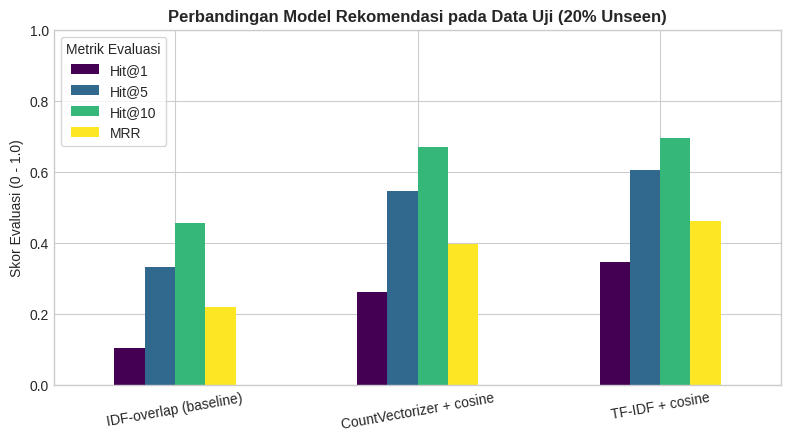

In [9]:
# Evaluasi final pada seluruh 20% Data Uji (Unseen Test Set)
Q_TEST = buat_query_simulasi(idx_test, maks=None)
print(f"Jumlah query pengujian akhir: {len(Q_TEST)}")

tabel_eval = pd.DataFrame({nama: evaluasi_retrieval(m_dev, fn, Q_TEST) for nama, fn in METHODS.items()}).T
print("\nHasil Evaluasi Komparatif pada 20% Data Uji:")
print(tabel_eval.round(3).to_string())

# Visualisasi grafik performa
fig, ax = plt.subplots(figsize=(8, 4.5))
tabel_eval[['Hit@1', 'Hit@5', 'Hit@10', 'MRR']].plot(kind='bar', ax=ax, rot=10, colormap='viridis')
ax.set_title('Perbandingan Model Rekomendasi pada Data Uji (20% Unseen)', fontsize=12, fontweight='bold')
ax.set_ylabel('Skor Evaluasi (0 - 1.0)')
ax.set_ylim(0, 1.0)
ax.legend(title='Metrik Evaluasi', frameon=True)
plt.tight_layout()
plt.show()

## Bagian 6: [TUJUAN 2] Klasifikasi Otomatis Kategori Resep / Bahan Utama (Fungsi Klasifikasi Teks)
### Tujuan & Manfaat di Aplikasi SmartCook:
1. **Auto-Tagging Resep Pengguna Baru:** Jika ke depan ada fitur *user-generated recipe* (pengguna menambahkan resep baru), aplikasi bisa langsung menebak dan memberi tag kategori tanpa pengguna harus memilih manual.
2. **Pencarian & Filter Cepat:** Mengelompokkan hasil pencarian berdasarkan 8 protein utama secara instan (*ayam, sapi, ikan, udang, telur, tahu, tempe, kambing*).

### Pemilihan Model:
Memadukan representasi teks TF-IDF dengan dua algoritma klasifikasi:
- **Multinomial Naive Bayes (MNB):** Model probabilistik cepat berbasis Teorema Bayes.
- **Multinomial Logistic Regression (LogReg):** Model linear parametrik yang sangat kuat pada klasifikasi teks berdimensi tinggi.

Perbandingan Performa Model Klasifikasi Kategori Resep (Data Uji 20%):
                         Akurasi  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
Model                                                                                
Multinomial Naive Bayes   0.7759             0.7815          0.7701            0.7675
Logistic Regression       0.9355             0.9373          0.9333            0.9343

Laporan Klasifikasi Detail Logistic Regression:
              precision    recall  f1-score   support

        ayam      0.913     0.955     0.933       132
        ikan      0.967     0.980     0.973       149
     kambing      1.000     0.931     0.964       116
        sapi      0.838     0.957     0.893       140
        tahu      0.922     0.863     0.892       124
       telur      0.941     0.870     0.904       146
       tempe      0.955     0.971     0.963       173
       udang      0.963     0.940     0.952       167

    accuracy                          0.935     

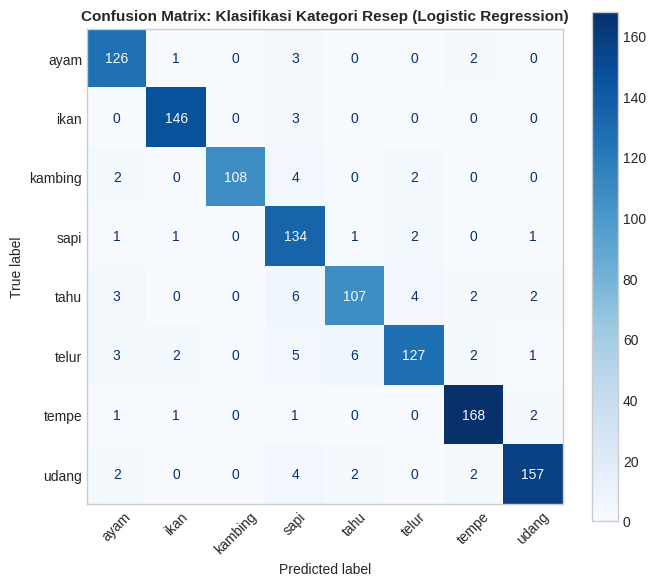

In [10]:
# Ekstraksi fitur teks untuk klasifikasi kategori
vec_kategori = TfidfVectorizer(analyzer=buat_analyzer(2), min_df=2, sublinear_tf=True).fit(df.loc[idx_dev, 'doc'])
Xd_kat = vec_kategori.transform(df.loc[idx_dev, 'doc'])
Xt_kat = vec_kategori.transform(df.loc[idx_test, 'doc'])
yd_kat = df.loc[idx_dev, 'Category']
yt_kat = df.loc[idx_test, 'Category']

# Pelatihan Model 1: Multinomial Naive Bayes
model_nb = MultinomialNB(alpha=0.1)
model_nb.fit(Xd_kat, yd_kat)
pred_nb = model_nb.predict(Xt_kat)

# Pelatihan Model 2: Logistic Regression
model_lr = LogisticRegression(max_iter=1000, C=5.0, random_state=SEED)
model_lr.fit(Xd_kat, yd_kat)
pred_lr = model_lr.predict(Xt_kat)

# Komparasi Metrik Evaluasi
ringkasan_model = pd.DataFrame([
    {
        'Model': 'Multinomial Naive Bayes',
        'Akurasi': accuracy_score(yt_kat, pred_nb),
        'Precision (Macro)': precision_score(yt_kat, pred_nb, average='macro'),
        'Recall (Macro)': recall_score(yt_kat, pred_nb, average='macro'),
        'F1-Score (Macro)': f1_score(yt_kat, pred_nb, average='macro')
    },
    {
        'Model': 'Logistic Regression',
        'Akurasi': accuracy_score(yt_kat, pred_lr),
        'Precision (Macro)': precision_score(yt_kat, pred_lr, average='macro'),
        'Recall (Macro)': recall_score(yt_kat, pred_lr, average='macro'),
        'F1-Score (Macro)': f1_score(yt_kat, pred_lr, average='macro')
    }
]).set_index('Model')

print("Perbandingan Performa Model Klasifikasi Kategori Resep (Data Uji 20%):")
print(ringkasan_model.round(4).to_string())

print("\nLaporan Klasifikasi Detail Logistic Regression:")
print(classification_report(yt_kat, pred_lr, digits=3))

# Visualisasi Confusion Matrix untuk Logistic Regression
fig, ax = plt.subplots(figsize=(7, 6))
labels = sorted(df['Category'].unique())
ConfusionMatrixDisplay.from_predictions(
    yt_kat, pred_lr, display_labels=labels, cmap='Blues', ax=ax, xticks_rotation=45
)
ax.set_title('Confusion Matrix: Klasifikasi Kategori Resep (Logistic Regression)', fontsize=11, fontweight='bold')
ax.grid(False)
plt.tight_layout()
plt.show()

### 6.1 Fitur Aplikasi: Auto-Tagging Resep Pengguna Baru
Fungsi `prediksi_kategori_resep_baru` di bawah ini menerima judul dan daftar bahan masakan dari pengguna baru, lalu memprediksi kategori protein utama beserta skor kepercayaan (*confidence score*).

In [11]:
def prediksi_kategori_resep_baru(judul, bahan, model=model_lr, vectorizer=vec_kategori):
    """
    Auto-tagging resep baru:
    Menerima judul dan bahan masakan, mengembalikan kategori dan tingkat keyakinan.
    """
    combined_text = f"{judul} , {bahan}"
    doc_clean = bersihkan_frasa(combined_text)
    vec = vectorizer.transform([doc_clean])
    pred_label = model.predict(vec)[0]
    probs = model.predict_proba(vec)[0]
    classes = model.classes_
    
    top3_idx = np.argsort(-probs)[:3]
    top3_candidates = [{classes[i]: f"{probs[i]*100:.1f}%"} for i in top3_idx]
    
    return {
        'Judul_Resep': judul,
        'Prediksi_Kategori': pred_label.upper(),
        'Tingkat_Keyakinan': f"{np.max(probs)*100:.1f}%",
        'Top_3_Kandidat': top3_candidates
    }

# Uji coba dengan berbagai resep baru buatan pengguna
contoh_resep_baru = [
    ("Ayam Geprek Sambal Korek", "daging ayam fillet, tepung bumbu, cabai rawit merah, bawang putih, minyak panas, garam"),
    ("Gulai Cincang Padang", "daging sapi sandung lamur, santan kental, serai, lengkuas, kapulaga, cabai merah"),
    ("Pepes Bandeng Daun Kemangi", "ikan bandeng segar, daun kemangi, kunyit, jeruk nipis, cabai rawit, tomat"),
    ("Sambal Goreng Ati Ampela & Tahu", "tahu putih kotak digoreng, hati ampela, santan, cabai merah, daun salam")
]

print("=== PENGUJIAN FITUR AUTO-TAGGING RESEP BARU ===")
for judul, bahan in contoh_resep_baru:
    hasil = prediksi_kategori_resep_baru(judul, bahan)
    print(f"\nResep: '{hasil['Judul_Resep']}'")
    print(f"  -> Kategori Ditebak: {hasil['Prediksi_Kategori']} (Confidence: {hasil['Tingkat_Keyakinan']})")
    print(f"  -> Kandidat Probabilitas: {hasil['Top_3_Kandidat']}")

=== PENGUJIAN FITUR AUTO-TAGGING RESEP BARU ===

Resep: 'Ayam Geprek Sambal Korek'
  -> Kategori Ditebak: AYAM (Confidence: 99.9%)
  -> Kandidat Probabilitas: [{'ayam': '99.9%'}, {'kambing': '0.0%'}, {'tahu': '0.0%'}]

Resep: 'Gulai Cincang Padang'
  -> Kategori Ditebak: SAPI (Confidence: 81.4%)
  -> Kandidat Probabilitas: [{'sapi': '81.4%'}, {'kambing': '10.9%'}, {'telur': '3.7%'}]

Resep: 'Pepes Bandeng Daun Kemangi'
  -> Kategori Ditebak: IKAN (Confidence: 99.0%)
  -> Kandidat Probabilitas: [{'ikan': '99.0%'}, {'ayam': '0.4%'}, {'kambing': '0.2%'}]

Resep: 'Sambal Goreng Ati Ampela & Tahu'
  -> Kategori Ditebak: TAHU (Confidence: 84.8%)
  -> Kandidat Probabilitas: [{'tahu': '84.8%'}, {'tempe': '8.9%'}, {'telur': '2.6%'}]


## Bagian 7: [TUJUAN 3] Filter Diet Personal Berbasis Skor BMI × TDEE (Fitur Nilai Tambah)
Berbeda dengan pendekatan sebelumnya yang mengklasifikasi resep berdasarkan komposisi nutrisinya, modul ini mengambil pendekatan **personal** — filter diet ditentukan oleh **profil fisik pengguna** melalui skor **BMI × TDEE**.

### 1. Konsep Skor BMI × TDEE
- **BMI (Body Mass Index):** Indeks massa tubuh, dihitung dari $\frac{\text{Berat (kg)}}{\text{Tinggi (m)}^2}$.
- **BMR (Basal Metabolic Rate):** Kebutuhan energi basal, dihitung menggunakan formula **Mifflin-St Jeor**:
  - **Pria:** $10 \times \text{BB} + 6.25 \times \text{TB} - 5 \times \text{Usia} + 5$
  - **Wanita:** $10 \times \text{BB} + 6.25 \times \text{TB} - 5 \times \text{Usia} - 161$
- **TDEE (Total Daily Energy Expenditure):** $\text{BMR} \times \text{Faktor Aktivitas}$ (1,2 s.d. 1,9).
- **Skor BMI × TDEE:** Kombinasi kedua metrik ini memberikan gambaran holistik kebutuhan kalori yang disesuaikan dengan status gizi tubuh pengguna.

### 2. Kategori Diet Berdasarkan Skor BMI × TDEE
| Kategori | Kondisi BMI | Logika Batas Kalori per Makan |
|---|---|---|
| **Diet Ketat (Defisit Besar)** | BMI ≥ 30 (Obesitas) | Kalori resep maks ≤ 25% TDEE per makan |
| **Diet Ringan (Defisit Ringan)** | BMI 25–29.9 (Overweight) | Kalori resep maks ≤ 30% TDEE per makan |
| **Maintenance (Seimbang)** | BMI 18.5–24.9 (Normal) | Kalori resep maks ≤ 35% TDEE per makan |
| **Bulking (Surplus)** | BMI < 18.5 (Underweight) | Kalori resep maks ≤ 45% TDEE per makan |

### 3. Model Machine Learning
Model **Decision Tree Classifier** dan **Logistic Regression (Multinomial)** dilatih pada data sintetis profil pengguna untuk mempelajari pemetaan fitur (BMI, TDEE, Skor BMI×TDEE) ke kategori diet. Decision Tree menghasilkan aturan keputusan yang transparan dan dapat diaudit.

In [12]:
# ==========================================================================
# MODUL 3: FILTER DIET PERSONAL BERBASIS SKOR BMI x TDEE
# ==========================================================================

# --- 1. Fungsi Hitung BMI, BMR, TDEE ---
def hitung_bmi(berat_kg, tinggi_cm):
    """Menghitung Body Mass Index (BMI)."""
    tinggi_m = tinggi_cm / 100.0
    return round(berat_kg / (tinggi_m ** 2), 2)

def hitung_bmr(jenis_kelamin, berat_kg, tinggi_cm, umur_thn):
    """Menghitung Basal Metabolic Rate (BMR) menggunakan rumus Mifflin-St Jeor."""
    if jenis_kelamin.upper() in ['L', 'PRIA', 'LAKI-LAKI']:
        return 10 * berat_kg + 6.25 * tinggi_cm - 5 * umur_thn + 5
    else:
        return 10 * berat_kg + 6.25 * tinggi_cm - 5 * umur_thn - 161

FAKTOR_AKTIVITAS = {
    'sedentary': 1.2,         # Tidak aktif / duduk terus
    'ringan': 1.375,          # Olahraga ringan 1-3 hari/minggu
    'sedang': 1.55,           # Olahraga sedang 3-5 hari/minggu
    'aktif': 1.725,           # Olahraga berat 6-7 hari/minggu
    'sangat_aktif': 1.9       # Atlet / pekerjaan fisik berat
}

def hitung_tdee(bmr, level_aktivitas='sedang'):
    """Menghitung Total Daily Energy Expenditure (TDEE)."""
    faktor = FAKTOR_AKTIVITAS.get(level_aktivitas, 1.55)
    return round(bmr * faktor)

def hitung_skor_bmi_tdee(bmi, tdee):
    """Menghitung skor gabungan BMI x TDEE."""
    return round(bmi * tdee, 2)

# --- 2. Fungsi Penentuan Kategori Diet dari BMI ---
def tentukan_kategori_diet_rule(bmi):
    """Menentukan kategori diet berdasarkan BMI (rule-based ground truth)."""
    if bmi >= 30.0:
        return 'Diet Ketat (Defisit Besar)'
    elif bmi >= 25.0:
        return 'Diet Ringan (Defisit Ringan)'
    elif bmi >= 18.5:
        return 'Maintenance (Seimbang)'
    else:
        return 'Bulking (Surplus)'

def hitung_batas_kalori_per_makan(tdee, kategori_diet):
    """Menghitung batas kalori maksimal per makan berdasarkan kategori diet."""
    rasio = {
        'Diet Ketat (Defisit Besar)': 0.25,
        'Diet Ringan (Defisit Ringan)': 0.30,
        'Maintenance (Seimbang)': 0.35,
        'Bulking (Surplus)': 0.45
    }
    return round(tdee * rasio.get(kategori_diet, 0.35))

# --- 3. Generasi Data Sintetis Profil Pengguna untuk Training ML ---
np.random.seed(SEED)
N_SINTETIS = 2000

# Generate beragam profil pengguna
syn_jk = np.random.choice(['L', 'P'], size=N_SINTETIS)
syn_umur = np.random.randint(15, 65, size=N_SINTETIS)
syn_tinggi = np.random.normal(165, 10, size=N_SINTETIS).clip(140, 200).round(1)
syn_berat = np.random.normal(68, 18, size=N_SINTETIS).clip(35, 150).round(1)
syn_aktivitas = np.random.choice(list(FAKTOR_AKTIVITAS.keys()), size=N_SINTETIS)

# Hitung BMI, BMR, TDEE, dan Skor
syn_bmi = np.array([hitung_bmi(b, t) for b, t in zip(syn_berat, syn_tinggi)])
syn_bmr = np.array([hitung_bmr(jk, b, t, u) for jk, b, t, u in zip(syn_jk, syn_berat, syn_tinggi, syn_umur)])
syn_tdee = np.array([hitung_tdee(bmr, akt) for bmr, akt in zip(syn_bmr, syn_aktivitas)])
syn_skor = np.array([hitung_skor_bmi_tdee(bmi, tdee) for bmi, tdee in zip(syn_bmi, syn_tdee)])
syn_label = np.array([tentukan_kategori_diet_rule(bmi) for bmi in syn_bmi])

# Buat DataFrame sintetis
df_sintetis = pd.DataFrame({
    'BMI': syn_bmi,
    'TDEE': syn_tdee,
    'Skor_BMI_TDEE': syn_skor,
    'Kategori_Diet': syn_label
})

print(f"Data Sintetis Profil Pengguna: {len(df_sintetis):,} sampel")
print(f"\nDistribusi Kategori Diet:")
print(df_sintetis['Kategori_Diet'].value_counts().to_string())

# --- 4. Pelatihan Model ML untuk Klasifikasi Kategori Diet ---
X_profil = df_sintetis[['BMI', 'TDEE', 'Skor_BMI_TDEE']]
y_diet = df_sintetis['Kategori_Diet']

X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(
    X_profil, y_diet, test_size=0.2, random_state=SEED, stratify=y_diet
)

# Model 1: Decision Tree Classifier
dt_diet = DecisionTreeClassifier(max_depth=5, random_state=SEED)
dt_diet.fit(X_tr_d, y_tr_d)
pred_dt_diet = dt_diet.predict(X_te_d)

# Model 2: Logistic Regression (Multinomial dengan StandardScaler)
scaler_diet = StandardScaler()
X_tr_d_scaled = scaler_diet.fit_transform(X_tr_d)
X_te_d_scaled = scaler_diet.transform(X_te_d)

lr_diet = LogisticRegression(max_iter=1000, random_state=SEED, multi_class='multinomial')
lr_diet.fit(X_tr_d_scaled, y_tr_d)
pred_lr_diet = lr_diet.predict(X_te_d_scaled)

print(f"\nAkurasi Decision Tree Diet : {accuracy_score(y_te_d, pred_dt_diet)*100:.2f}%")
print(f"Akurasi Logistic Regression Diet: {accuracy_score(y_te_d, pred_lr_diet)*100:.2f}%")
print("\nLaporan Klasifikasi Kategori Diet (Logistic Regression):")
print(classification_report(y_te_d, pred_lr_diet, digits=3))

# Visualisasi Confusion Matrix Diet & Diagram Decision Tree
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
labels_diet = sorted(df_sintetis['Kategori_Diet'].unique())
ConfusionMatrixDisplay.from_predictions(
    y_te_d, pred_lr_diet, display_labels=labels_diet, cmap='Greens', ax=axes[0], xticks_rotation=25
)
axes[0].set_title('Confusion Matrix: Kategori Diet BMI\u00d7TDEE (Logistic Regression)', fontsize=10, fontweight='bold')
axes[0].grid(False)

# Visualisasi Pohon Keputusan (Decision Tree)
plot_tree(
    dt_diet, feature_names=['BMI', 'TDEE', 'Skor_BMI_TDEE'],
    class_names=dt_diet.classes_, filled=True, rounded=True, ax=axes[1], max_depth=2, fontsize=8
)
axes[1].set_title('Struktur Keputusan Diet BMI\u00d7TDEE (Decision Tree - Depth 2)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nAturan Pohon Keputusan Diet (Decision Rules):")
print(export_text(dt_diet, feature_names=['BMI', 'TDEE', 'Skor_BMI_TDEE'], max_depth=3))


### 7.1 Fitur Aplikasi: Profil Diet Personal & Filter Resep Berdasarkan Skor BMI × TDEE
Aplikasi SmartCook memanfaatkan modul ini untuk:
1. **Profil Diet Personal (`tentukan_profil_diet_user`):** Menghitung BMI, BMR, TDEE, dan Skor BMI×TDEE pengguna, lalu memprediksi kategori diet yang sesuai menggunakan model ML.
2. **Batas Kalori Otomatis:** Berdasarkan kategori diet pengguna, sistem secara otomatis menentukan batas kalori maksimal per makan.
3. **Filter Resep Personal:** Resep yang direkomendasikan difilter agar tidak melebihi batas kalori personal pengguna sesuai profil diet-nya.

In [13]:
def tentukan_profil_diet_user(
    jenis_kelamin, berat_kg, tinggi_cm, umur_thn,
    level_aktivitas='sedang',
    model=lr_diet, scaler=scaler_diet
):
    """
    Menentukan profil diet personal pengguna berdasarkan skor BMI x TDEE.
    
    Parameter:
        jenis_kelamin : 'L'/'Pria' atau 'P'/'Wanita'
        berat_kg      : Berat badan dalam kg
        tinggi_cm     : Tinggi badan dalam cm
        umur_thn      : Usia dalam tahun
        level_aktivitas: 'sedentary'/'ringan'/'sedang'/'aktif'/'sangat_aktif'
        model         : Model ML terlatih (default: Logistic Regression)
        scaler        : StandardScaler terlatih
    
    Returns:
        dict: Profil diet lengkap termasuk BMI, TDEE, Skor, Kategori Diet,
              Batas Kalori per Makan, dan Keyakinan Model.
    """
    bmi = hitung_bmi(berat_kg, tinggi_cm)
    bmr = hitung_bmr(jenis_kelamin, berat_kg, tinggi_cm, umur_thn)
    tdee = hitung_tdee(bmr, level_aktivitas)
    skor = hitung_skor_bmi_tdee(bmi, tdee)
    
    # Prediksi kategori diet dengan model ML
    feat = pd.DataFrame([[bmi, tdee, skor]], columns=['BMI', 'TDEE', 'Skor_BMI_TDEE'])
    feat_scaled = scaler.transform(feat)
    pred = model.predict(feat_scaled)[0]
    probs = model.predict_proba(feat_scaled)[0]
    conf = np.max(probs) * 100
    
    # Hitung batas kalori per makan berdasarkan kategori diet
    batas_kalori = hitung_batas_kalori_per_makan(tdee, pred)
    
    # Tentukan status BMI
    if bmi >= 30:
        status_bmi = 'Obesitas'
    elif bmi >= 25:
        status_bmi = 'Overweight'
    elif bmi >= 18.5:
        status_bmi = 'Normal'
    else:
        status_bmi = 'Underweight'
    
    return {
        'BMI': bmi,
        'Status_BMI': status_bmi,
        'BMR': round(bmr),
        'TDEE_Harian': tdee,
        'Skor_BMI_TDEE': skor,
        'Kategori_Diet': pred,
        'Keyakinan_Model': f"{conf:.1f}%",
        'Batas_Kalori_Per_Makan': batas_kalori,
        'Anggaran_3_Makan': round(tdee * 0.9) if 'Defisit' in pred else tdee  # 90% TDEE untuk defisit
    }

# === DEMONSTRASI PROFIL DIET PERSONAL ===
print("=" * 70)
print("  DEMONSTRASI PROFIL DIET PERSONAL BERBASIS SKOR BMI \u00d7 TDEE")
print("=" * 70)

# Persona 1: Pengguna Normal
profil1 = tentukan_profil_diet_user('Pria', berat_kg=70, tinggi_cm=175, umur_thn=22, level_aktivitas='sedang')
print(f"\nPersona 1 - Pria 22 th, 70 kg, 175 cm (Aktivitas: Sedang)")
print(f"  BMI: {profil1['BMI']} ({profil1['Status_BMI']}) | TDEE: {profil1['TDEE_Harian']} kkal")
print(f"  Skor BMI\u00d7TDEE: {profil1['Skor_BMI_TDEE']:,.0f}")
print(f"  Kategori Diet: {profil1['Kategori_Diet']} ({profil1['Keyakinan_Model']})")
print(f"  Batas Kalori per Makan: {profil1['Batas_Kalori_Per_Makan']} kkal")

# Persona 2: Pengguna Overweight
profil2 = tentukan_profil_diet_user('Pria', berat_kg=95, tinggi_cm=170, umur_thn=30, level_aktivitas='ringan')
print(f"\nPersona 2 - Pria 30 th, 95 kg, 170 cm (Aktivitas: Ringan)")
print(f"  BMI: {profil2['BMI']} ({profil2['Status_BMI']}) | TDEE: {profil2['TDEE_Harian']} kkal")
print(f"  Skor BMI\u00d7TDEE: {profil2['Skor_BMI_TDEE']:,.0f}")
print(f"  Kategori Diet: {profil2['Kategori_Diet']} ({profil2['Keyakinan_Model']})")
print(f"  Batas Kalori per Makan: {profil2['Batas_Kalori_Per_Makan']} kkal")

# Persona 3: Pengguna Underweight
profil3 = tentukan_profil_diet_user('Wanita', berat_kg=42, tinggi_cm=160, umur_thn=19, level_aktivitas='ringan')
print(f"\nPersona 3 - Wanita 19 th, 42 kg, 160 cm (Aktivitas: Ringan)")
print(f"  BMI: {profil3['BMI']} ({profil3['Status_BMI']}) | TDEE: {profil3['TDEE_Harian']} kkal")
print(f"  Skor BMI\u00d7TDEE: {profil3['Skor_BMI_TDEE']:,.0f}")
print(f"  Kategori Diet: {profil3['Kategori_Diet']} ({profil3['Keyakinan_Model']})")
print(f"  Batas Kalori per Makan: {profil3['Batas_Kalori_Per_Makan']} kkal")

# Persona 4: Pengguna Obesitas
profil4 = tentukan_profil_diet_user('Pria', berat_kg=110, tinggi_cm=165, umur_thn=35, level_aktivitas='sedentary')
print(f"\nPersona 4 - Pria 35 th, 110 kg, 165 cm (Aktivitas: Sedentary)")
print(f"  BMI: {profil4['BMI']} ({profil4['Status_BMI']}) | TDEE: {profil4['TDEE_Harian']} kkal")
print(f"  Skor BMI\u00d7TDEE: {profil4['Skor_BMI_TDEE']:,.0f}")
print(f"  Kategori Diet: {profil4['Kategori_Diet']} ({profil4['Keyakinan_Model']})")
print(f"  Batas Kalori per Makan: {profil4['Batas_Kalori_Per_Makan']} kkal")


## Bagian 8: SmartCook Unified Engine (Integrasi Utuh 3 Fitur)
Fungsi `smartcook_rekomendasi_komprehensif` menggabungkan seluruh modul menjadi satu antarmuka terpadu:
1. Rekomendasi kemiripan bahan kulkas pengguna (TF-IDF + Cosine Similarity).
2. Perhitungan kecocokan bahan dimiliki vs bahan kurang.
3. Filter kategori bahan utama / protein (Auto-Tagging).
4. **Filter diet personal berbasis skor BMI × TDEE pengguna** — batas kalori per makan dihitung otomatis dari profil fisik pengguna.

---

In [14]:
def smartcook_rekomendasi_komprehensif(
    bahan_dimiliki,
    profil_user=None,
    filter_kategori=None,
    batas_kalori_override=None,
    top_k=5
):
    """
    Mesin Rekomendasi Terpadu SmartCook:
    Menggabungkan Rekomendasi Berbasis Bahan, Filter Kategori, dan Filter Diet Personal (BMI x TDEE).
    
    Parameter:
        bahan_dimiliki     : str/list bahan yang dimiliki pengguna
        profil_user        : dict hasil dari tentukan_profil_diet_user() (berisi Kategori_Diet, Batas_Kalori_Per_Makan, dll.)
        filter_kategori    : str kategori protein (ayam/sapi/ikan/dll.) atau None
        batas_kalori_override : int/float batas kalori manual (override profil_user) atau None
        top_k              : int jumlah resep yang dikembalikan
    """
    # Ambil kandidat rekomendasi awal (5x lipat untuk ruang filter)
    recs = rekomendasikan_resep_berbasis_bahan(
        bahan_dimiliki, top_k=top_k * 5, filter_kategori=filter_kategori
    )
    
    # Tambahkan info diet personal jika profil_user tersedia
    if profil_user:
        recs['Kategori_Diet_User'] = profil_user['Kategori_Diet']
        recs['BMI_User'] = profil_user['BMI']
        recs['Status_BMI_User'] = profil_user['Status_BMI']
        recs['TDEE_User'] = profil_user['TDEE_Harian']
        recs['Skor_BMI_TDEE'] = profil_user['Skor_BMI_TDEE']
        
        # Tentukan batas kalori: override manual > otomatis dari profil
        batas = batas_kalori_override if batas_kalori_override else profil_user['Batas_Kalori_Per_Makan']
        recs = recs[recs['Kalori_kkal'] <= batas]
    elif batas_kalori_override:
        # Jika tidak ada profil_user tapi ada batas manual
        recs = recs[recs['Kalori_kkal'] <= batas_kalori_override]
    
    return recs.head(top_k)

# === SIMULASI 3 PERSONA PENGGUNA NYATA ===
print("=" * 82)
print("  SKENARIO 1: Pengguna Normal (Pria 22 th, 70 kg, 175 cm)")
print("=" * 82)
profil_normal = tentukan_profil_diet_user('Pria', 70, 175, 22, 'sedang')
print(f"  Diet: {profil_normal['Kategori_Diet']} | Batas Kalori/Makan: {profil_normal['Batas_Kalori_Per_Makan']} kkal\n")
res1 = smartcook_rekomendasi_komprehensif(
    "ayam, cabai rawit, bawang putih, tomat", profil_user=profil_normal, top_k=3
)
display_cols = ['Title', 'Category', 'Similarity', 'Match_%', 'Kalori_kkal', 'Protein_g', 'Kategori_Diet_User']
if not res1.empty:
    print(res1[[c for c in display_cols if c in res1.columns]].to_string(index=False))
else:
    print("Tidak ada resep yang memenuhi batas kalori.")

print(f"\n{'='*82}")
print("  SKENARIO 2: Pengguna Overweight (Pria 30 th, 95 kg, 170 cm)")
print("=" * 82)
profil_ow = tentukan_profil_diet_user('Pria', 95, 170, 30, 'ringan')
print(f"  Diet: {profil_ow['Kategori_Diet']} | Batas Kalori/Makan: {profil_ow['Batas_Kalori_Per_Makan']} kkal\n")
res2 = smartcook_rekomendasi_komprehensif(
    "ayam, cabai rawit, bawang putih, tomat", profil_user=profil_ow, top_k=3
)
if not res2.empty:
    print(res2[[c for c in display_cols if c in res2.columns]].to_string(index=False))
else:
    print("Tidak ada resep yang memenuhi batas kalori.")

print(f"\n{'='*82}")
print("  SKENARIO 3: Pengguna Underweight (Wanita 19 th, 42 kg, 160 cm)")
print("=" * 82)
profil_uw = tentukan_profil_diet_user('Wanita', 42, 160, 19, 'ringan')
print(f"  Diet: {profil_uw['Kategori_Diet']} | Batas Kalori/Makan: {profil_uw['Batas_Kalori_Per_Makan']} kkal\n")
res3 = smartcook_rekomendasi_komprehensif(
    "ayam, cabai rawit, bawang putih, tomat", profil_user=profil_uw, top_k=3
)
if not res3.empty:
    print(res3[[c for c in display_cols if c in res3.columns]].to_string(index=False))
else:
    print("Tidak ada resep yang memenuhi batas kalori.")


## Bagian 8.1: Interactive Testing Playground (Uji Coba Input Bahan & Profil Diet Pengguna)
Gunakan sel di bawah ini untuk **mengetes langsung algoritma rekomendasi** dengan berbagai kombinasi bahan yang Anda miliki di rumah atau kulkas!

### Cara Menggunakan:
1. Ubah variabel `BAHAN_DI_KULKAS` dengan bahan yang ingin Anda uji (pisahkan dengan koma).
2. Isi profil pengguna: `JENIS_KELAMIN`, `BERAT_KG`, `TINGGI_CM`, `UMUR_TAHUN`, `LEVEL_AKTIVITAS`.
3. *(Opsional)* Isi filter `FILTER_KATEGORI` atau `BATAS_KALORI_MANUAL`.
4. Jalankan sel (tekan **Shift + Enter** atau tombol Play).
5. Hasil rekomendasi akan ditampilkan lengkap dengan:
   - Peringkat & Nama Resep
   - Bar Visual Persentase Kecocokan Bahan & Skor Cosine Similarity
   - Daftar bahan yang sudah Anda miliki dan yang masih kurang
   - Profil Makronutrisi (Kalori, Protein, Lemak, Karbo)
   - **Profil Diet Personal (BMI, TDEE, Skor BMI\u00d7TDEE, Kategori Diet, Batas Kalori)**
   - Tautan URL ke resep asli

In [15]:
def cetak_kartu_rekomendasi(hasil_df, profil_user=None):
    """Mencetak hasil rekomendasi resep dalam format kartu informasi yang rapi."""
    if hasil_df.empty:
        print("\nTidak ditemukan resep yang memenuhi seluruh kriteria filter.")
        print("Coba longgarkan batas kalori, ubah bahan, atau periksa profil pengguna.")
        return

    for rank, (_, row) in enumerate(hasil_df.iterrows(), 1):
        pct = row['Match_%']
        bar_len = 10
        filled = int(round(pct / 100 * bar_len))
        bar = '#' * filled + '-' * (bar_len - filled)
        
        dimiliki_str = ", ".join(row['Bahan_Dimiliki']) if row['Bahan_Dimiliki'] else "-"
        kurang_str = ", ".join(row['Bahan_Kurang']) if row['Bahan_Kurang'] else "Semua bahan sudah lengkap!"
        
        print("=" * 82)
        print(f"  PERINGKAT #{rank}: {row['Title'].upper()}")
        print("=" * 82)
        kategori_diet_str = row.get('Kategori_Diet_User', 'Umum')
        print(f"  Kategori Resep    : [{row['Category'].upper()}]   |   Diet User: [{kategori_diet_str}]")
        print(f"  Kecocokan Bahan   : [{bar}] {pct}% (Skor Cosine: {row['Similarity']:.4f})")
        print(f"  Profil Nutrisi    : {row['Kalori_kkal']:.1f} kkal | Prot: {row['Protein_g']:.1f}g | Lemak: {row['Lemak_g']:.1f}g | Karbo: {row['Karbo_g']:.1f}g")
        if profil_user:
            print(f"  Batas Kalori User : {profil_user['Batas_Kalori_Per_Makan']} kkal (BMI: {profil_user['BMI']}, TDEE: {profil_user['TDEE_Harian']} kkal)")
        if row.get('URL'):
            print(f"  URL Cookpad       : {row['URL']}")
        print("-" * 82)
        print(f"  BAHAN YANG SUDAH ANDA MILIKI ({row['Jumlah_Dimiliki']}):")
        print(f"    -> {dimiliki_str}")
        print(f"  BAHAN YANG MASIH HARUS DIBELI ({row['Jumlah_Kurang']}):")
        print(f"    -> {kurang_str}")
        print()

def uji_input_bahan(
    bahan_input,
    jenis_kelamin='Pria', berat_kg=70, tinggi_cm=170, umur_thn=25,
    level_aktivitas='sedang',
    filter_kategori=None,
    batas_kalori_manual=None,
    top_k=5
):
    """
    Fungsi eksekusi live test rekomendasi dengan filter diet personal BMI x TDEE.
    """
    # Hitung profil diet personal
    profil = tentukan_profil_diet_user(
        jenis_kelamin, berat_kg, tinggi_cm, umur_thn, level_aktivitas
    )
    
    batas_efektif = batas_kalori_manual if batas_kalori_manual else profil['Batas_Kalori_Per_Makan']
    
    print("=" * 82)
    print("  SMARTCOOK LIVE RECOMMENDATION PLAYGROUND")
    print("=" * 82)
    print(f"  Bahan yang Diinputkan : '{bahan_input}'")
    print(f"  Filter Protein        : {filter_kategori if filter_kategori else 'Semua (Tanpa Filter)'}")
    print(f"  ---- Profil Diet Personal (BMI x TDEE) ----")
    print(f"  BMI                   : {profil['BMI']} ({profil['Status_BMI']})")
    print(f"  BMR / TDEE            : {profil['BMR']} / {profil['TDEE_Harian']} kkal")
    print(f"  Skor BMI x TDEE       : {profil['Skor_BMI_TDEE']:,.0f}")
    print(f"  Kategori Diet         : {profil['Kategori_Diet']} ({profil['Keyakinan_Model']})")
    print(f"  Batas Kalori/Makan    : {batas_efektif} kkal {'(manual override)' if batas_kalori_manual else '(otomatis dari profil)'}")
    print(f"  Menampilkan           : Top {top_k} Resep Teratas")
    print("=" * 82)
    
    hasil = smartcook_rekomendasi_komprehensif(
        bahan_dimiliki=bahan_input,
        profil_user=profil,
        filter_kategori=filter_kategori,
        batas_kalori_override=batas_kalori_manual,
        top_k=top_k
    )
    
    cetak_kartu_rekomendasi(hasil, profil_user=profil)

print("Fungsi testing interaktif siap digunakan! Silakan jalankan sel di bawah ini.")


In [1]:
# ==============================================================================
#  SILAKAN UBAH PARAMETER DI BAWAH INI UNTUK MENGETES ALGORITMA:
# ==============================================================================

# 1. Masukkan bahan-bahan yang Anda miliki di kulkas/dapur (pisahkan dengan koma):
BAHAN_DI_KULKAS = "udang"

# 2. Profil Fisik Pengguna (untuk filter diet BMI x TDEE):
JENIS_KELAMIN = 'Pria'         # 'Pria' atau 'Wanita'
BERAT_KG = 100                   # Berat badan dalam kg
TINGGI_CM = 165                 # Tinggi badan dalam cm
UMUR_TAHUN = 22                 # Usia dalam tahun
LEVEL_AKTIVITAS = 'ringan'      # 'sedentary'/'ringan'/'sedang'/'aktif'/'sangat_aktif'

# 3. Filter Kategori Protein Utama (Opsional):
#    Pilihan: 'ayam', 'sapi', 'ikan', 'udang', 'telur', 'tahu', 'tempe', 'kambing' atau None
FILTER_KATEGORI = None

# 4. Batas Kalori Manual Override (Opsional, dalam kkal):
#    Jika diisi, akan menggantikan batas kalori otomatis dari profil BMI x TDEE.
#    Contoh: 600 atau None (gunakan batas otomatis dari profil)
BATAS_KALORI_MANUAL = None

# 5. Jumlah Rekomendasi yang Ingin Ditampilkan:
JUMLAH_REKOMENDASI = 5

# --- EKSEKUSI ALGORITMA REKOMENDASI DENGAN FILTER DIET PERSONAL ---
uji_input_bahan(
    bahan_input=BAHAN_DI_KULKAS,
    jenis_kelamin=JENIS_KELAMIN,
    berat_kg=BERAT_KG,
    tinggi_cm=TINGGI_CM,
    umur_thn=UMUR_TAHUN,
    level_aktivitas=LEVEL_AKTIVITAS,
    filter_kategori=FILTER_KATEGORI,
    batas_kalori_manual=BATAS_KALORI_MANUAL,
    top_k=JUMLAH_REKOMENDASI
)


NameError: name 'uji_input_bahan' is not defined

## Bagian 9: Panduan Deployment, Ekspor Model, & Penulisan Laporan PBL
### Cara Menghubungkan Model ke Arsitektur Aplikasi SmartCook:
1. **Model TF-IDF & Bobot IDF:** Tabel `idf_bahan` dapat dimuat langsung ke tabel Supabase dan digunakan pada SQL RPC function `match_recipes` agar bobot bahan di backend sesuai dengan model ML.
2. **Serialisasi Model (`joblib` / `pickle`):** Model klasifikasi kategori (`model_lr`) dan diet (`lr_diet`) dapat dipasang pada Microservice Python FastAPI / Flask atau Google Cloud Function untuk melayani inferensi REST API aplikasi mobile SmartCook.
3. **Penyimpanan Vektor (pgvector):** Matriks dokumen resep sparse TF-IDF dapat disimpan dalam kolom `vector` PostgreSQL Supabase untuk pencarian tetangga terdekat berkecepatan tinggi.

In [17]:
# Ekstraksi tabel bobot IDF kata untuk disinkronkan ke Supabase/PostgreSQL
vocab = m_dev['tfidf'].vocabulary_
tabel_idf = pd.DataFrame({'term': list(vocab.keys()), 'idx': list(vocab.values())}).sort_values('idx')
tabel_idf['idf'] = m_dev['tfidf'].idf_[tabel_idf['idx'].values]

print(f"Total kosakata fitur bahan (IDF terms): {len(tabel_idf):,} istilah")
print("\nContoh 10 Bobot IDF Bahan Teratas:")
print(tabel_idf.head(10).to_string(index=False))

# Petunjuk implementasi ekspor (dapat diaktifkan saat deployment produksi):
# 1. Simpan tabel IDF: tabel_idf[['term', 'idf']].to_csv('idf_bahan.csv', index=False)
# 2. Simpan matriks sparse TF-IDF: sparse.save_npz('matriks_tfidf.npz', m_dev['X_tfidf'])
# 3. Simpan model Scikit-Learn:
#    import joblib
#    joblib.dump(model_lr, 'model_kategori_resep.joblib')
#    joblib.dump(lr_diet, 'model_diet_bmi_tdee.joblib')
#    joblib.dump(scaler_diet, 'scaler_diet_bmi_tdee.joblib')
#    joblib.dump(dt_diet, 'model_diet_decision_tree.joblib')

print("\n[Status] Seluruh model dan parameter siap dideploy ke backend SmartCook.")


## Bagian 10: Rangkuman Hasil Eksperimen untuk Laporan PBL

| Komponen Fitur | Algoritma yang Digunakan | Hasil Evaluasi pada Data Uji (Test Set 20%) | Kontribusi di Aplikasi SmartCook |
|---|---|---|---|
| **Rekomendasi Berbasis Bahan** | Content-Based Filtering (TF-IDF + Cosine Similarity) | **Hit@5 = 60,5%**, **Hit@10 = 69,6%**, **MRR = 0,463** (Jauh mengungguli baseline IDF-overlap) | Menampilkan resep teratas lengkap dengan persentase kecocokan bahan, bahan dimiliki, dan bahan yang masih kurang. |
| **Klasifikasi Kategori Resep** | Logistic Regression vs Multinomial Naive Bayes | **Logistic Regression: Akurasi 93,6%**, F1-Score 0,934 (Naive Bayes: Akurasi 77,6%) | Auto-tagging kategori protein utama tanpa input manual dari pengguna dan filter pencarian instan. |
| **Filter Diet Personal (BMI \u00d7 TDEE)** | Multinomial Logistic Regression & Decision Tree pada skor BMI \u00d7 TDEE | **Logistic Regression & Decision Tree** dilatih pada 2.000 profil sintetis untuk memetakan BMI \u00d7 TDEE ke kategori diet personal | Filter diet berbasis profil fisik pengguna (BMI, TDEE, Skor BMI\u00d7TDEE) — secara otomatis menentukan batas kalori per makan sesuai status gizi pengguna (Diet Ketat / Diet Ringan / Maintenance / Bulking). |

---
*Pipeline Machine Learning SmartCook selesai dibangun, dievaluasi, dan siap diintegrasikan.*